<a href="https://colab.research.google.com/github/anthony-yt/deepwater-image-segmentation-classical-quantum/blob/feat%2Fuwsegformer-finetuning/notebooks/4_uwsegformer_supervised_finetuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UWSegFormer — Fine-Tuning supervisado en imágenes CLAHE

Este notebook parte de la evidencia cualitativa del notebook de inferencia: SUIM activa más regiones, pero sobre-segmenta; DUT es excesivamente conservador. Por ello se reutiliza SUIM, se reemplaza únicamente el clasificador final por una salida binaria y se congela el encoder completo.

**Objetivo:** ajustar la cabeza `MAA_segformer1` usando imágenes CLAHE y las máscaras auditadas por Anthony y Ariana, registrando pérdida, mIoU y Dice en validación.

**Supuesto de etiquetado:** las máscaras representan segmentación binaria: `0 = fondo`, `1 = estructura/objeto`. La preparación convierte cualquier valor mayor que cero en primer plano. Cambia `INVERT_MASKS` si una auditoría visual muestra máscaras invertidas.

> Ejecuta con GPU en Colab (`Runtime → Change runtime type → T4 GPU`). La primera instalación de `condacolab` reinicia el runtime; después continúa desde la celda siguiente.

## 1. Entorno legacy reproducible

In [92]:
# Ejecutar una sola vez. condacolab reiniciará el runtime automáticamente.
try:
    import google.colab  # noqa: F401
except ImportError as exc:
    raise RuntimeError("Este notebook está diseñado para Google Colab.") from exc

try:
    import condacolab
    print("condacolab ya está disponible.")
except ImportError:
    !pip install -q condacolab==0.1.9
    import condacolab
    condacolab.install()

condacolab ya está disponible.


In [106]:
# Crea un entorno aislado con las versiones que funcionaron para UWSegFormer.
import subprocess

envs_output = subprocess.check_output(["conda", "env", "list"], text=True)
existing_envs = [line.split()[0] for line in envs_output.splitlines() if line and not line.startswith("#")]

if "uws" in existing_envs:
    print("El entorno 'uws' existe. Eliminándolo para una instalación limpia...")
    !conda env remove -n uws -y
    print("Entorno 'uws' eliminado.")

print("Creando el entorno 'uws' e instalando dependencias...")
!conda create -n uws python=3.8 -y
!conda run -n uws python -m pip install --upgrade pip
!conda run -n uws python -m pip install torch==1.10.2+cu111 torchvision==0.11.3+cu111 -f https://download.pytorch.org/whl/torch_stable.html
!conda run -n uws python -m pip install mmcv-full==1.5.3 -f https://download.openmmlab.com/mmcv/dist/cu111/torch1.10/index.html
!conda run -n uws python -m pip install mmsegmentation==0.11.0 opencv-python matplotlib pandas pillow ipython
!conda run -n uws python -m pip install scipy timm==0.4.12 kornia terminaltables yapf==0.40.1 addict packaging
print("Entorno 'uws' creado y dependencias instaladas.")

El entorno 'uws' existe. Eliminándolo para una instalación limpia...

Remove all packages in environment /usr/local/envs/uws:

Entorno 'uws' eliminado.
Creando el entorno 'uws' e instalando dependencias...
Channels:
 - conda-forge
Platform: linux-64
Solving environment: / - done


==> WARNING: A newer version of conda exists. <==
    current version: 23.11.0
    latest version: 26.7.2

Please update conda by running

    $ conda update -n base -c conda-forge conda



## Package Plan ##

  environment location: /usr/local/envs/uws

  added / updated specs:
    - python=3.8


The following NEW packages will be INSTALLED:

  _openmp_mutex      conda-forge/linux-64::_openmp_mutex-4.5-20_gnu 
  bzip2              conda-forge/linux-64::bzip2-1.0.8-hda65f42_10 
  ca-certificates    conda-forge/noarch::ca-certificates-2026.7.22-hbd8a1cb_0 
  icu                conda-forge/linux-64::icu-78.3-py310h44b86e0_2 
  ld_impl_linux-64   conda-forge/linux-64::ld_impl_linux-64-2.46.1-default_hbd61a6d

In [107]:
# Verificación obligatoria antes de preparar datos o entrenar.
!conda run -n uws python -c "import sys, torch, mmcv; print('Python:', sys.version.split()[0]); print('Torch:', torch.__version__); print('MMCV:', mmcv.__version__); assert sys.version_info[:2] == (3, 8); assert torch.__version__.startswith('1.10.2'); assert mmcv.__version__ == '1.5.3'; assert torch.cuda.is_available(), 'Activa GPU en Colab'"
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv,noheader

Python: 3.8.20
Torch: 1.10.2+cu111
MMCV: 1.5.3

Tesla T4, 15360 MiB, 580.82.07


## 2. Drive, rutas y parámetros del experimento

In [108]:
from google.colab import drive
drive.mount('/content/drive')

import json
import os
import random
import re
import shutil
import subprocess
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 42
VALIDATION_FRACTION = 0.20
MAX_ITERS = 2000
EVAL_INTERVAL = 100
CHECKPOINT_INTERVAL = 250
SAMPLES_PER_GPU = 2
WORKERS_PER_GPU = 2
LEARNING_RATE = 6e-5
INVERT_MASKS = False

DRIVE_ROOT = Path('/content/drive/MyDrive/Under_Water_Dataset')
PROCESSED_ROOT = DRIVE_ROOT / 'Dataset_Processed'
CLAHE_DIR = PROCESSED_ROOT / 'Frames_CLAHE'
SAM_MASK_DIR = PROCESSED_ROOT / 'SAM_Masks_Frames_CLAHE'
CURATED_DIR = PROCESSED_ROOT / 'Test_Set_Curado'
FALLBACK_IMAGE_DIRS = [PROCESSED_ROOT / 'Dataset_Final_512', PROCESSED_ROOT / 'Frames_Crudos']

CHECKPOINT = DRIVE_ROOT / 'checkpoints' / 'uws_SUIM.pth'
if not CHECKPOINT.exists():
    CHECKPOINT = Path('/content/drive/MyDrive/Under_Water_Dataset/checkpoints/uws_SUIM.pth')

UWSEGFORMER_ROOT = Path('/content/UWSegFormer')
DATASET_ROOT = Path('/content/uwsegformer_binary_dataset')
EXPERIMENT_ROOT = DRIVE_ROOT / 'experiments' / 'uwsegformer_binary_head_finetune'
EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=True)

settings = {
    'seed': SEED,
    'validation_fraction': VALIDATION_FRACTION,
    'max_iters': MAX_ITERS,
    'eval_interval': EVAL_INTERVAL,
    'checkpoint_interval': CHECKPOINT_INTERVAL,
    'samples_per_gpu': SAMPLES_PER_GPU,
    'workers_per_gpu': WORKERS_PER_GPU,
    'learning_rate': LEARNING_RATE,
    'invert_masks': INVERT_MASKS,
    'clahe_dir': str(CLAHE_DIR),
    'ariana_mask_dir': str(SAM_MASK_DIR),
    'anthony_curated_dir': str(CURATED_DIR),
    'checkpoint': str(CHECKPOINT),
    'dataset_root': str(DATASET_ROOT),
    'experiment_root': str(EXPERIMENT_ROOT),
}
display(pd.Series(settings, name='value'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,value
seed,42
validation_fraction,0.2
max_iters,2000
eval_interval,100
checkpoint_interval,250
samples_per_gpu,2
workers_per_gpu,2
learning_rate,0.00006
invert_masks,False
clahe_dir,/content/drive/MyDrive/Under_Water_Dataset/Dat...


In [109]:
# Comprobaciones tempranas con mensajes accionables.
required_paths = {
    'Frames_CLAHE': CLAHE_DIR,
    'SAM masks': SAM_MASK_DIR,
    'Test set curado ': CURATED_DIR,
    'Checkpoint SUIM': CHECKPOINT,
}
missing = {name: path for name, path in required_paths.items() if not path.exists()}
for name, path in required_paths.items():
    print(f"{'OK' if path.exists() else 'MISSING':7} {name}: {path}")
if missing:
    raise FileNotFoundError('Faltan rutas requeridas:\n' + '\n'.join(f'- {k}: {v}' for k, v in missing.items()))

OK      Frames_CLAHE: /content/drive/MyDrive/Under_Water_Dataset/Dataset_Processed/Frames_CLAHE
OK      SAM masks: /content/drive/MyDrive/Under_Water_Dataset/Dataset_Processed/SAM_Masks_Frames_CLAHE
OK      Test set curado : /content/drive/MyDrive/Under_Water_Dataset/Dataset_Processed/Test_Set_Curado
OK      Checkpoint SUIM: /content/drive/MyDrive/Under_Water_Dataset/checkpoints/uws_SUIM.pth


## 3. Código UWSegFormer y parches reproducibles

In [110]:
UWS_COMMIT = 'b61fa450bad58137b3ab8fecd1e7f7cedba4ce57'
if not UWSEGFORMER_ROOT.exists():
    !git clone https://github.com/SAWRJJ/UWSegFormer.git /content/UWSegFormer
!git -C /content/UWSegFormer checkout {UWS_COMMIT}

# Parche 1: el upstream importa nombres antiguos que ya no existen.
decode_init = UWSEGFORMER_ROOT / 'mmseg/models/decode_heads/__init__.py'
text = decode_init.read_text()
text = text.replace(
    'from .segformer_head import PPMobileSegHead_segformer2,PPMobileSegHead_segformer1',
    'from .segformer_head import MAA_segformer1',
)
text = text.replace(
    "    'PPMobileSegHead_segformer2',\n    'PPMobileSegHead_segformer1'",
    "    'MAA_segformer1'",
)
decode_init.write_text(text)

# Parche 2: las rutas base de ambos configs apuntan un nivel demasiado arriba.
for config_path in (UWSEGFORMER_ROOT / 'local_configs/uwsegformer').glob('*.py'):
    config_path.write_text(config_path.read_text().replace('../../_base_/', '../_base_/'))

assert 'from .segformer_head import MAA_segformer1' in decode_init.read_text()
SUIM_CONFIG = UWSEGFORMER_ROOT / 'local_configs/uwsegformer/segformer_e+PPsegHead1.b0.640x480.suim.160k.py'
assert SUIM_CONFIG.exists()
print('UWSegFormer listo en', UWSEGFORMER_ROOT)

M	local_configs/uwsegformer/segformer_e+PPsegHead1.b0.640x480.dut.40k.py
M	local_configs/uwsegformer/segformer_e+PPsegHead1.b0.640x480.suim.160k.py
M	mmseg/models/decode_heads/__init__.py
HEAD is now at b61fa45 init
UWSegFormer listo en /content/UWSegFormer


## 4. Emparejar y auditar imágenes/máscaras

Se priorizan imágenes de `Frames_CLAHE`. Para una máscara que no tenga allí una imagen con el mismo identificador, se buscan alternativas en `Test_Set_Curado`, `Dataset_Final_512` y `Frames_Crudos`.

El split es determinista y se hace por video, no por frame, para reducir fuga temporal entre entrenamiento y validación.

In [111]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

def canonical_stem(path_or_name):
    stem = Path(path_or_name).stem
    stem = re.sub(r'\s*\(\d+\)$', '', stem)
    stem = re.sub(r'_mask$', '', stem, flags=re.IGNORECASE)
    stem = re.sub(r'^aug_\d+_', '', stem, flags=re.IGNORECASE)
    return re.sub(r'[^a-z0-9]+', '', stem.lower())

def list_images(root, include_masks=False):
    paths = []
    if root.exists():
        for path in root.rglob('*'):
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
                if include_masks or 'mask' not in path.stem.lower():
                    paths.append(path)
    return sorted(paths)

image_roots = [CLAHE_DIR, CURATED_DIR, *FALLBACK_IMAGE_DIRS]
image_index = {}
for priority, root in enumerate(image_roots):
    for path in list_images(root, include_masks=False):
        image_index.setdefault(canonical_stem(path), (priority, path))

mask_candidates = []
for source, priority, root in [
    ('anthony', 0, CURATED_DIR),
    ('ariana', 1, SAM_MASK_DIR),
]:
    for path in list_images(root, include_masks=True):
        if 'mask' in path.stem.lower():
            mask_candidates.append((priority, source, path))

# Una sola máscara por frame; Anthony tiene prioridad ante duplicados.
mask_index = {}
for priority, source, mask_path in sorted(mask_candidates):
    mask_index.setdefault(canonical_stem(mask_path), (source, mask_path))

records, unmatched = [], []
for key, (source, mask_path) in sorted(mask_index.items()):
    image_match = image_index.get(key)
    if image_match is None:
        unmatched.append({'source': source, 'mask': str(mask_path), 'key': key})
        continue
    image_priority, image_path = image_match
    records.append({
        'key': key,
        'source': source,
        'image_path': image_path,
        'mask_path': mask_path,
        'image_root_priority': image_priority,
    })

pairs = pd.DataFrame(records)
if pairs.empty:
    raise RuntimeError('No se encontró ningún par imagen/máscara. Revisa nombres y rutas.')

print(f'Máscaras únicas: {len(mask_index)}')
print(f'Pares encontrados: {len(pairs)}')
print(f'Máscaras sin imagen: {len(unmatched)}')
display(pairs.groupby(['source', 'image_root_priority']).size().rename('pairs').reset_index())
if unmatched:
    display(pd.DataFrame(unmatched).head(20))

Máscaras únicas: 20
Pares encontrados: 20
Máscaras sin imagen: 0


,source,image_root_priority,pairs
0,anthony,0,20


In [112]:
def read_binary_mask(mask_path):
    mask = cv2.imread(str(mask_path), cv2.IMREAD_UNCHANGED)
    if mask is None:
        raise ValueError(f'No se pudo leer {mask_path}')
    if mask.ndim == 3:
        # SAM puede exportar RGB/RGBA; cualquier canal positivo es foreground.
        mask = np.max(mask[..., :3], axis=2)
    binary = (mask > 0).astype(np.uint8)
    if INVERT_MASKS:
        binary = 1 - binary
    return binary

audit_rows = []
for row in pairs.itertuples(index=False):
    image = cv2.imread(str(row.image_path), cv2.IMREAD_COLOR)
    mask = read_binary_mask(row.mask_path)
    if image is None:
        raise ValueError(f'No se pudo leer {row.image_path}')
    audit_rows.append({
        'key': row.key,
        'source': row.source,
        'image_h': image.shape[0],
        'image_w': image.shape[1],
        'mask_h': mask.shape[0],
        'mask_w': mask.shape[1],
        'foreground_ratio': float(mask.mean()),
        'same_size': image.shape[:2] == mask.shape[:2],
    })

audit = pd.DataFrame(audit_rows)
display(audit.groupby('source')['foreground_ratio'].describe())
print('Pares con dimensiones distintas:', int((~audit.same_size).sum()))

median_fg = audit.foreground_ratio.median()
if not 0.001 < median_fg < 0.999:
    raise ValueError(
        f'La mediana de foreground ({median_fg:.4f}) es sospechosa. '
        'Revisa las máscaras y el parámetro INVERT_MASKS.'
    )

,count,mean,std,min,25%,50%,75%,max
source,,,,,,,,
anthony,20.0,0.717826,0.081869,0.558733,0.680014,0.707613,0.773009,0.911024


Pares con dimensiones distintas: 0


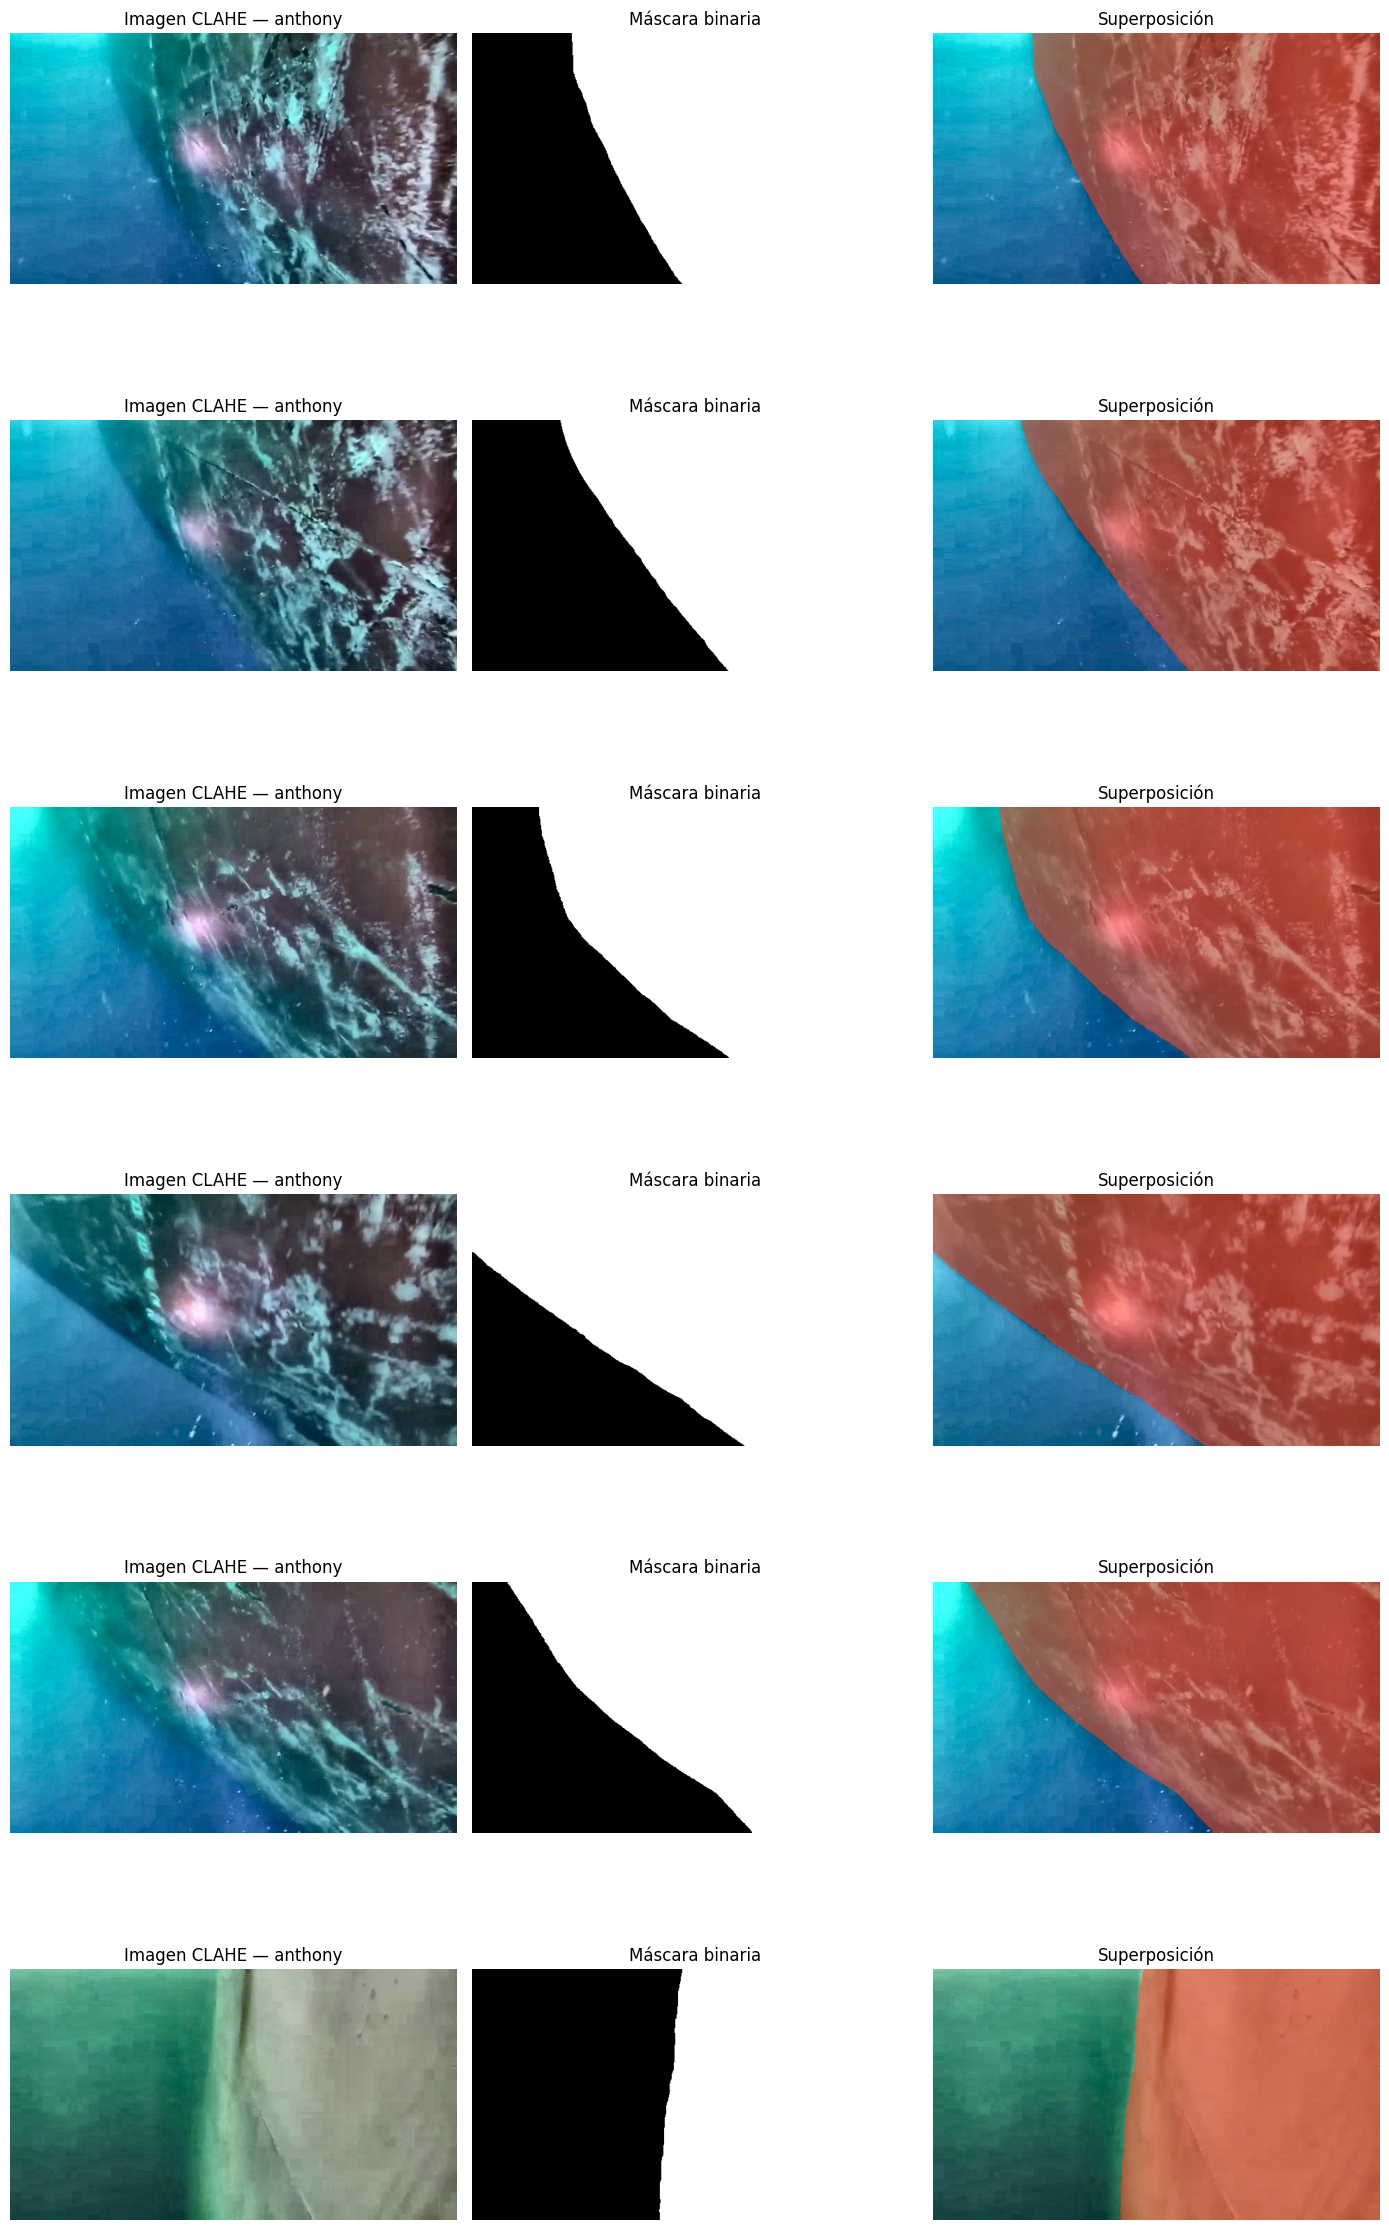

In [113]:
# Inspección visual obligatoria antes de entrenar.
rng = np.random.default_rng(SEED)
sample_ids = rng.choice(len(pairs), size=min(6, len(pairs)), replace=False)
fig, axes = plt.subplots(len(sample_ids), 3, figsize=(14, 4 * len(sample_ids)))
if len(sample_ids) == 1:
    axes = np.array([axes])
for ax_row, idx in zip(axes, sample_ids):
    row = pairs.iloc[idx]
    image_bgr = cv2.imread(str(row.image_path))
    image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    mask = read_binary_mask(row.mask_path)
    if mask.shape != image.shape[:2]:
        mask = cv2.resize(mask, (image.shape[1], image.shape[0]), interpolation=cv2.INTER_NEAREST)
    overlay = image.copy()
    overlay[mask == 1] = (0.45 * overlay[mask == 1] + 0.55 * np.array([255, 70, 40])).astype(np.uint8)
    ax_row[0].imshow(image); ax_row[0].set_title(f"Imagen CLAHE — {row['source']}")
    ax_row[1].imshow(mask, cmap='gray', vmin=0, vmax=1); ax_row[1].set_title('Máscara binaria')
    ax_row[2].imshow(overlay); ax_row[2].set_title('Superposición')
    for ax in ax_row: ax.axis('off')
plt.tight_layout()
plt.show()

In [114]:
def video_group(name):
    match = re.search(r'(deepwater[-_]?video\d+)', name, flags=re.IGNORECASE)
    return match.group(1).lower().replace('_', '-') if match else canonical_stem(name)

pairs['group'] = [video_group(Path(path).stem) for path in pairs.mask_path]
groups = sorted(pairs.group.unique())
rng = random.Random(SEED)
rng.shuffle(groups)

if len(groups) >= 2:
    target_val = max(1, round(len(pairs) * VALIDATION_FRACTION))
    val_groups, val_count = [], 0
    for group in groups:
        if val_count >= target_val and val_groups:
            break
        val_groups.append(group)
        val_count += int((pairs.group == group).sum())
    if len(val_groups) == len(groups):
        val_groups = val_groups[:-1]
    pairs['split'] = np.where(pairs.group.isin(val_groups), 'validation', 'training')
else:
    # Fallback para un único video: split determinista por frame.
    order = np.arange(len(pairs))
    np.random.default_rng(SEED).shuffle(order)
    val_n = max(1, round(len(pairs) * VALIDATION_FRACTION))
    pairs['split'] = 'training'
    pairs.loc[pairs.index[order[:val_n]], 'split'] = 'validation'

if (pairs.split == 'training').sum() == 0 or (pairs.split == 'validation').sum() == 0:
    raise RuntimeError('El split no produjo ejemplos en training y validation.')

display(pairs.groupby(['split', 'source']).size().unstack(fill_value=0))
print('Grupos de validación:', sorted(pairs.loc[pairs.split == 'validation', 'group'].unique()))

source,anthony
split,
training,16
validation,4


Grupos de validación: ['deepwater-video1']


In [115]:
# Materializa un dataset limpio para CustomDataset de MMSegmentation.
if DATASET_ROOT.exists():
    shutil.rmtree(DATASET_ROOT)
for split in ('training', 'validation'):
    (DATASET_ROOT / 'images' / split).mkdir(parents=True, exist_ok=True)
    (DATASET_ROOT / 'annotations' / split).mkdir(parents=True, exist_ok=True)

manifest_rows = []
for idx, row in pairs.reset_index(drop=True).iterrows():
    image = cv2.imread(str(row.image_path), cv2.IMREAD_COLOR)
    mask = read_binary_mask(row.mask_path)
    if mask.shape != image.shape[:2]:
        mask = cv2.resize(mask, (image.shape[1], image.shape[0]), interpolation=cv2.INTER_NEAREST)
    sample_id = f"{idx:04d}_{row['key']}"
    image_out = DATASET_ROOT / 'images' / row.split / f'{sample_id}.jpg'
    mask_out = DATASET_ROOT / 'annotations' / row.split / f'{sample_id}.png'
    if not cv2.imwrite(str(image_out), image, [cv2.IMWRITE_JPEG_QUALITY, 95]):
        raise IOError(f'No se pudo escribir {image_out}')
    if not cv2.imwrite(str(mask_out), mask.astype(np.uint8)):
        raise IOError(f'No se pudo escribir {mask_out}')
    manifest_rows.append({
        'sample_id': sample_id,
        'split': row.split,
        'source': row.source,
        'group': row.group,
        'original_image': str(row.image_path),
        'original_mask': str(row.mask_path),
        'foreground_ratio': float(mask.mean()),
    })

manifest = pd.DataFrame(manifest_rows)
manifest.to_csv(EXPERIMENT_ROOT / 'dataset_manifest.csv', index=False)
print(manifest.groupby('split').size())

split
training      16
validation     4
dtype: int64


## 5. Configuración de fine-tuning y congelamiento del encoder

In [116]:
# El script usa el trainer legacy de MMSegmentation, elimina solo el clasificador
# SUIM de 6 clases y congela todos los parámetros de model.backbone.
TRAIN_SCRIPT = Path('/content/train_uwsegformer_frozen.py')
TRAIN_SCRIPT.write_text(r'''
import copy
import json
import os
import sys
import time
from pathlib import Path

import numpy as np
np.float = float  # compatibilidad con NumPy >= 1.20 y mmseg 0.11
np.int = int

import mmcv
import torch
from mmcv.runner import load_checkpoint
from mmcv.utils import Config, get_git_hash

ROOT = Path('/content/UWSegFormer')
sys.path.insert(0, str(ROOT))

from mmseg import __version__
from mmseg.apis import set_random_seed, train_segmentor
from mmseg.datasets import build_dataset
from mmseg.models import build_segmentor
from mmseg.utils import get_root_logger

SETTINGS = json.loads(Path('/content/uws_settings.json').read_text())
DATA_ROOT = SETTINGS['dataset_root']
WORK_DIR = SETTINGS['experiment_root']
SOURCE_CHECKPOINT = Path(SETTINGS['checkpoint'])

cfg = Config.fromfile(str(ROOT / 'local_configs/uwsegformer/segformer_e+PPsegHead1.b0.640x480.suim.160k.py'))
cfg.model.pretrained = None
cfg.model.decode_head.num_classes = 2
cfg.model.decode_head.loss_decode = dict(type='CrossEntropyLoss', use_sigmoid=False, loss_weight=1.0)

img_norm_cfg = dict(mean=[123.675, 116.28, 103.53], std=[58.395, 57.12, 57.375], to_rgb=True)
crop_size = (480, 640)
train_pipeline = [
    dict(type='LoadImageFromFile'),
    dict(type='LoadAnnotations', reduce_zero_label=False),
    dict(type='Resize', img_scale=(640, 480), ratio_range=(0.8, 1.2)),
    dict(type='RandomCrop', crop_size=crop_size, cat_max_ratio=0.90),
    dict(type='RandomFlip', prob=0.5),
    dict(type='Normalize', **img_norm_cfg),
    dict(type='Pad', size=crop_size, pad_val=0, seg_pad_val=255),
    dict(type='DefaultFormatBundle'),
    dict(type='Collect', keys=['img', 'gt_semantic_seg']),
]
test_pipeline = [
    dict(type='LoadImageFromFile'),
    dict(type='MultiScaleFlipAug', img_scale=(640, 480), flip=False, transforms=[
        dict(type='Resize', keep_ratio=True),
        dict(type='RandomFlip'),
        dict(type='Normalize', **img_norm_cfg),
        dict(type='Pad', size=crop_size, pad_val=0, seg_pad_val=255),
        dict(type='ImageToTensor', keys=['img']),
        dict(type='Collect', keys=['img']),
    ]),
]
common_dataset = dict(
    type='CustomDataset',
    data_root=DATA_ROOT,
    img_suffix='.jpg',
    seg_map_suffix='.png',
    classes=('background', 'structure'),
    palette=[[0, 0, 0], [255, 80, 40]],
)
cfg.data = dict(
    samples_per_gpu=SETTINGS['samples_per_gpu'],
    workers_per_gpu=SETTINGS['workers_per_gpu'],
    train=dict(**common_dataset, img_dir='images/training', ann_dir='annotations/training', pipeline=train_pipeline),
    val=dict(**common_dataset, img_dir='images/validation', ann_dir='annotations/validation', pipeline=test_pipeline),
    test=dict(**common_dataset, img_dir='images/validation', ann_dir='annotations/validation', pipeline=test_pipeline),
)
cfg.optimizer = dict(type='AdamW', lr=SETTINGS['learning_rate'], betas=(0.9, 0.999), weight_decay=0.01)
cfg.optimizer_config = dict()
cfg.lr_config = dict(policy='poly', warmup='linear', warmup_iters=min(100, SETTINGS['max_iters'] // 10), warmup_ratio=1e-3, power=1.0, min_lr=1e-7, by_epoch=False)
cfg.runner = dict(type='IterBasedRunner', max_iters=SETTINGS['max_iters'])
cfg.checkpoint_config = dict(by_epoch=False, interval=SETTINGS['checkpoint_interval'], max_keep_ckpts=3)
cfg.evaluation = dict(interval=SETTINGS['eval_interval'], metric=['mIoU', 'mDice'], pre_eval=False)
cfg.log_config = dict(interval=20, hooks=[dict(type='TextLoggerHook', by_epoch=False)])
cfg.workflow = [('train', 1)]
cfg.work_dir = WORK_DIR
cfg.gpu_ids = [0]
cfg.seed = SETTINGS['seed']
cfg.resume_from = None
cfg.load_from = None
cfg.log_level = 'INFO'
cfg.find_unused_parameters = True

mmcv.mkdir_or_exist(WORK_DIR)
cfg.dump(str(Path(WORK_DIR) / 'uwsegformer_frozen_binary_config.py'))
timestamp = time.strftime('%Y%m%d_%H%M%S', time.localtime())
logger = get_root_logger(log_file=str(Path(WORK_DIR) / f'{timestamp}.log'), log_level=cfg.log_level)
set_random_seed(cfg.seed, deterministic=True)

model = build_segmentor(cfg.model)

# Carga controlada: conservar encoder y decoder SUIM, descartando solo el
# clasificador final de 6 clases. load_state_dict(strict=False) no tolera una
# forma distinta, por eso las dos claves se retiran explícitamente.
checkpoint = torch.load(str(SOURCE_CHECKPOINT), map_location='cpu')
state_dict = checkpoint.get('state_dict', checkpoint)
state_dict = {k.replace('module.', '', 1) if k.startswith('module.') else k: v for k, v in state_dict.items()}
removed = {}
for key in list(state_dict):
    if key in {'decode_head.conv_seg.weight', 'decode_head.conv_seg.bias'}:
        removed[key] = tuple(state_dict.pop(key).shape)
model_state = model.state_dict()
backbone_numel = sum(value.numel() for key, value in model_state.items() if key.startswith('backbone.'))
matched_backbone_numel = sum(
    value.numel()
    for key, value in state_dict.items()
    if key.startswith('backbone.') and key in model_state and tuple(value.shape) == tuple(model_state[key].shape)
)
backbone_coverage = matched_backbone_numel / max(backbone_numel, 1)
print(f'Cobertura del checkpoint sobre el encoder: {backbone_coverage:.2%}')
if backbone_coverage < 0.90:
    raise RuntimeError(
        f'El checkpoint solo cubre {backbone_coverage:.2%} del encoder; '
        'no es seguro continuar con el encoder congelado.'
    )
incompatible = model.load_state_dict(state_dict, strict=False)
print('Clasificador SUIM descartado:', removed)
print('Missing keys:', incompatible.missing_keys)
print('Unexpected keys:', incompatible.unexpected_keys)
expected_missing = {'decode_head.conv_seg.weight', 'decode_head.conv_seg.bias'}
if not expected_missing.issubset(set(incompatible.missing_keys)):
    raise RuntimeError('No se detectó el reemplazo esperado del clasificador final.')

for parameter in model.backbone.parameters():
    parameter.requires_grad = False

frozen = sum(p.numel() for p in model.backbone.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
assert frozen > 0 and trainable > 0
assert not any(p.requires_grad for p in model.backbone.parameters())
assert any(p.requires_grad for p in model.decode_head.parameters())
print(f'Parámetros totales: {total:,}')
print(f'Encoder congelado: {frozen:,}')
print(f'Parámetros entrenables (decoder/head): {trainable:,}')

datasets = [build_dataset(cfg.data.train)]
cfg.checkpoint_config['meta'] = dict(
    mmseg_version=f'{__version__}+{get_git_hash()[:7]}',
    config=cfg.pretty_text,
    CLASSES=datasets[0].CLASSES,
    PALETTE=datasets[0].PALETTE,
    source_checkpoint=str(SOURCE_CHECKPOINT),
    encoder_frozen=True,
)
model.CLASSES = datasets[0].CLASSES
model.PALETTE = datasets[0].PALETTE

meta = dict(
    seed=cfg.seed,
    exp_name='uwsegformer_frozen_binary',
    source_checkpoint=str(SOURCE_CHECKPOINT),
    encoder_frozen=True,
)
train_segmentor(model, datasets, cfg, distributed=False, validate=True, timestamp=timestamp, meta=meta)
''')

Path('/content/uws_settings.json').write_text(json.dumps(settings, indent=2))
print(TRAIN_SCRIPT)

/content/train_uwsegformer_frozen.py


In [117]:
# Entrenamiento supervisado. En una T4 puede tardar varios minutos.
!LD_LIBRARY_PATH=/usr/local/envs/uws/lib:$LD_LIBRARY_PATH conda run -n uws python /content/train_uwsegformer_frozen.py

Cobertura del checkpoint sobre el encoder: 100.00%
Clasificador SUIM descartado: {'decode_head.conv_seg.weight': (6, 128, 1, 1), 'decode_head.conv_seg.bias': (6,)}
Missing keys: ['decode_head.conv_seg.weight', 'decode_head.conv_seg.bias']
Unexpected keys: ['backbone.mtc.encoder.layer.0.channel_attn.query1.2.weight', 'backbone.mtc.encoder.layer.0.channel_attn.query1.3.weight', 'backbone.mtc.encoder.layer.0.channel_attn.query2.2.weight', 'backbone.mtc.encoder.layer.0.channel_attn.query2.3.weight', 'backbone.mtc.encoder.layer.0.channel_attn.query3.2.weight', 'backbone.mtc.encoder.layer.0.channel_attn.query3.3.weight', 'backbone.mtc.encoder.layer.0.channel_attn.query4.2.weight', 'backbone.mtc.encoder.layer.0.channel_attn.query4.3.weight', 'backbone.mtc.encoder.layer.0.channel_attn.key.2.weight', 'backbone.mtc.encoder.layer.0.channel_attn.key.3.weight', 'backbone.mtc.encoder.layer.0.channel_attn.value.2.weight', 'backbone.mtc.encoder.layer.0.channel_attn.value.3.weight', 'backbone.mtc.encod

## 6. Curvas de entrenamiento y métricas de validación

In [118]:
log_files = sorted(EXPERIMENT_ROOT.glob('*.log.json'), key=lambda p: p.stat().st_mtime)
if not log_files:
    raise FileNotFoundError(f'No se encontraron logs JSON en {EXPERIMENT_ROOT}')
log_path = log_files[-1]
rows = []
for line in log_path.read_text().splitlines():
    try:
        rows.append(json.loads(line))
    except json.JSONDecodeError:
        pass
history = pd.DataFrame(rows)
print('Log:', log_path)
display(history.tail())

Log: /content/drive/MyDrive/Under_Water_Dataset/experiments/uwsegformer_binary_head_finetune/20260924_045617.log.json


,seed,exp_name,source_checkpoint,encoder_frozen,mode,epoch,iter,lr,memory,data_time,decode.loss_seg,decode.acc_seg,loss,time,mIoU,mDice,mAcc,aAcc
96,NaN,NaN,NaN,NaN,train,240.0,1920.0,0.0,191.0,0.27342,0.03757,67.86423,0.03757,0.35924,NaN,NaN,NaN,NaN
97,NaN,NaN,NaN,NaN,train,243.0,1940.0,0.0,191.0,0.37452,0.03231,67.76562,0.03231,0.47963,NaN,NaN,NaN,NaN
98,NaN,NaN,NaN,NaN,train,245.0,1960.0,0.0,191.0,0.25257,0.03171,69.12353,0.03171,0.35430,NaN,NaN,NaN,NaN
99,NaN,NaN,NaN,NaN,train,248.0,1980.0,0.0,191.0,0.36698,0.03159,68.58112,0.03159,0.45805,NaN,NaN,NaN,NaN
100,NaN,NaN,NaN,NaN,val,250.0,2000.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.6862,0.8114,0.8816,0.8271


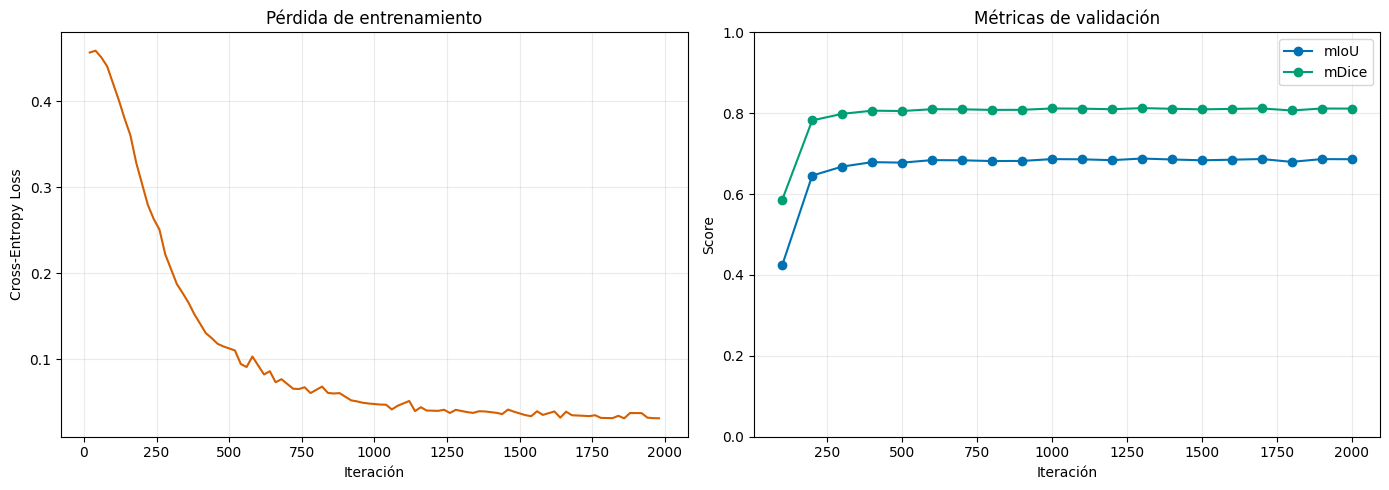

Curvas guardadas en: /content/drive/MyDrive/Under_Water_Dataset/experiments/uwsegformer_binary_head_finetune/training_curves.png


In [119]:
train_history = history[history.get('mode', pd.Series(index=history.index, dtype=str)).eq('train')].copy()
val_history = history[history.get('mode', pd.Series(index=history.index, dtype=str)).eq('val')].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if {'iter', 'loss'}.issubset(train_history.columns):
    loss_data = train_history[['iter', 'loss']].dropna()
    axes[0].plot(loss_data['iter'], loss_data['loss'], color='#D55E00', linewidth=1.5)
    axes[0].set(title='Pérdida de entrenamiento', xlabel='Iteración', ylabel='Cross-Entropy Loss')
else:
    axes[0].text(0.5, 0.5, 'Loss no encontrada en el log', ha='center')

metric_columns = [col for col in ('mIoU', 'mDice') if col in val_history.columns]
for metric, color in zip(metric_columns, ('#0072B2', '#009E73')):
    metric_data = val_history[['iter', metric]].dropna()
    axes[1].plot(metric_data['iter'], metric_data[metric], marker='o', label=metric, color=color)
axes[1].set(title='Métricas de validación', xlabel='Iteración', ylabel='Score', ylim=(0, 1))
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
curve_path = EXPERIMENT_ROOT / 'training_curves.png'
plt.savefig(curve_path, dpi=180, bbox_inches='tight')
plt.show()
print('Curvas guardadas en:', curve_path)

In [120]:
metric_columns = [col for col in ('mIoU', 'mDice', 'mAcc', 'aAcc') if col in val_history.columns]
if not metric_columns:
    raise RuntimeError('El log no contiene métricas de validación.')
metrics_table = val_history[['iter', *metric_columns]].dropna(subset=metric_columns, how='all').copy()
display(metrics_table)
best_idx = metrics_table['mIoU'].idxmax() if 'mIoU' in metrics_table else metrics_table.index[-1]
best_metrics = metrics_table.loc[best_idx].to_dict()
(EXPERIMENT_ROOT / 'best_validation_metrics.json').write_text(json.dumps(best_metrics, indent=2))
print('Mejor validación registrada:')
display(pd.Series(best_metrics))

,iter,mIoU,mDice,mAcc,aAcc
5,100.0,0.4245,0.5860,0.6194,0.6201
10,200.0,0.6458,0.7822,0.8608,0.7967
15,300.0,0.6680,0.7984,0.8724,0.8136
20,400.0,0.6790,0.8063,0.8779,0.8218
25,500.0,0.6778,0.8054,0.8773,0.8209
30,600.0,0.6840,0.8099,0.8804,0.8255
35,700.0,0.6836,0.8096,0.8803,0.8252
40,800.0,0.6817,0.8082,0.8793,0.8237
45,900.0,0.6820,0.8084,0.8795,0.8240
50,1000.0,0.6865,0.8117,0.8818,0.8273


Mejor validación registrada:


,0
iter,1300.0000
mIoU,0.6879
mDice,0.8126
mAcc,0.8824
aAcc,0.8283


- Se descartó correctamente ynicamente el clasificador SUIM de seis clases.
- Se congelaron 16,662,624 parametros.
- Solo se entrenaron 151,170 parametros, aproximadamente el 0.9% del modelo.
- Las claves inesperadas son 48 tensores adicionales presentes en el checkpoint, pero no falto ningún parámetro requerido del encoder actual.

El resultado por clase en la iteración 1,300 demuestra algo importante:
- Estructura: IoU 76.49%, Dice 86.68%, recall 76.49%.
- Fondo: recall 99.99%.
Eso indica que la sobre-segmentacion original fue controlada, casi ningún píxel de fondo se convierte incorrectamente en estructura.

El modelo ahora tiene una ligera tendencia conservadora y todavia omite alrededor del 23.5% de los píxeles de estructura.
Tener en cuenta que fueron 16 imagenes de entrenamiento y solamente 4 de validacion. Es un resultado excelente como prueba de concepto pero todavia no permite afirmar generalización robusta